# 19 · Project: a position servo from measured data to a digital controller

**Problem.** A position servo - the course's DC motor, a gearbox and a position sensor - is to be controlled
digitally. Three measurements exist: the motor's speed step response, a PRBS experiment, and a sine-sweep
frequency response of the whole servo, which shows something the motor model does not contain. The task:
identify the motor; find what else the servo contains and bound it as model uncertainty; design a controller
that meets a 2 % settling time of 0.5 s on a 10 rad step (about a turn and a half) without exceeding the 12 V
supply, with a phase margin of 45° and robust stability against the unmodelled part; implement it at a
sampling rate justified by the analysis; verify by simulation with the saturation; and report.

**What you will learn**
- identify a plant from time- and frequency-domain data and model what the data show
- bound the remaining uncertainty and let the limits set the bandwidth
- compare classical and state-space designs against the full specification
- discretise, verify with saturation, and report

**Before you start:** the whole course  ·  **Time:** about 4 h

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize as sopt
from englincontrol import systems as sy, identify as idf, design as dg, discrete as dc, frequency as fr, response as rs, robust as rb, stability as st, polynomials as pl, datasets, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. The motor from the PRBS data

In [2]:
p = pd.read_csv(datasets.path("motor_prbs.csv"), comment="#")
p = p[p.t_s >= 2.0]
u = (p.V - p.V.mean()).to_numpy(); yv = (p.speed_rad_s - p.speed_rad_s.mean()).to_numpy()
oe = idf.output_error(u[::10], yv[::10], 2, 0.05)
Gm_d = oe["tf"]
Gm = dc.d2c(Gm_d.to_ss())                                            # continuous motor model: voltage -> speed
Gm_tf = Gm.to_tf()
print("identified motor (voltage -> speed):", Gm_tf, "\n  poles", np.round(Gm_tf.poles().real, 3), " dc gain", round(Gm_tf.dcgain(), 3), "rad/s per V")
true = models.dc_motor(R=2.0, L=0.1, Kt=0.05, Ke=0.05, J=0.002, b=0.005)["system"].to_tf()
print("  (the plant that generated the data:", true, ")")

identified motor (voltage -> speed): TransferFunction(0.2682s + 247.3 / s^2 + 22.15s + 61.65) 
  poles [-18.888  -3.264]  dc gain 4.011 rad/s per V
  (the plant that generated the data: TransferFunction(250 / s^2 + 22.5s + 62.5) )


## 2. The servo's frequency response: what the motor model misses

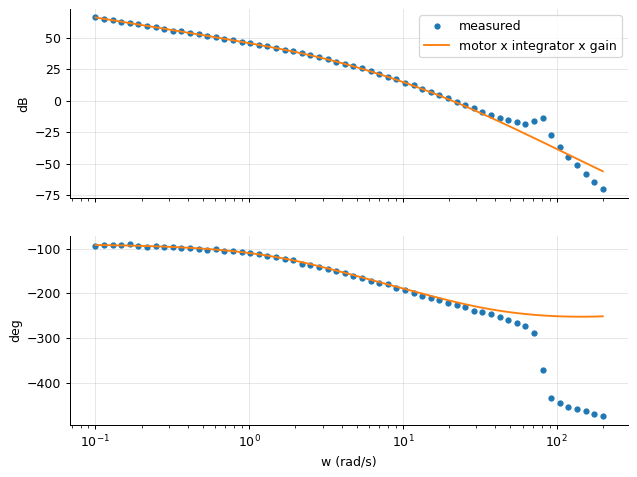

overall gain 49.7; the measured/model ratio reaches 9.3 near 81 rad/s (a resonance) and the phase falls below the model's by an amount growing with frequency (a delay)
joint fit: resonance wr = 80.0 rad/s, zeta = 0.051, delay = 4.0 ms; residual gain error 0.37 dB, phase error 3.1 deg


In [3]:
s_ = pd.read_csv(datasets.path("servo_frequency_response.csv"), comment="#")
w = s_.w_rad_s.to_numpy(); H = 10 ** (s_.gain_dB.to_numpy() / 20) * np.exp(1j * np.radians(s_.phase_deg.to_numpy()))
P0 = sy.series(Gm_tf, sy.tf([1.0], [1.0, 0.0]))                       # motor speed -> position: an integrator
gear = np.median(np.abs(H[:10]) / np.abs(fr.freqresp(P0, w[:10])))    # overall gain (gearbox, sensor) from the low-frequency data
P0 = sy.tf(gear * P0.num, P0.den)
H0 = fr.freqresp(P0, w)
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].semilogx(w, s_.gain_dB, "o", ms=4, label="measured"); axes[0].semilogx(w, 20 * np.log10(np.abs(H0)), label="motor x integrator x gain"); axes[0].legend(); axes[0].set_ylabel("dB")
axes[1].semilogx(w, s_.phase_deg, "o", ms=4); axes[1].semilogx(w, np.degrees(np.unwrap(np.angle(H0)))); axes[1].set_ylabel("deg"); axes[1].set_xlabel("w (rad/s)")
plt.show()
print(f"overall gain {gear:.1f}; the measured/model ratio reaches {np.max(np.abs(H / H0)):.1f} near {w[np.argmax(np.abs(H / H0))]:.0f} rad/s (a resonance) and the phase falls below the model's by an amount growing with frequency (a delay)")
def mismatch(theta):                                                  # fit a resonance and a delay jointly to the ratio data/model
    wr, zr, L = theta
    model = fr.freqresp(sy.series(P0, sy.tf([wr**2], [1.0, 2 * zr * wr, wr**2])), w, delay=L)
    return np.r_[np.log(np.abs(H / model)), np.angle(H / model)]
fit = sopt.least_squares(mismatch, [60.0, 0.1, 0.002], bounds=([20, 0.01, 0], [200, 1.0, 0.05]))
wr, zr, delay = fit.x
P_nom = sy.series(P0, sy.tf([wr**2], [1.0, 2 * zr * wr, wr**2]))     # the nominal model: motor, integrator, gain, resonance (the delay kept separately)
resid = H / fr.freqresp(P_nom, w, delay=delay)
print(f"joint fit: resonance wr = {wr:.1f} rad/s, zeta = {zr:.3f}, delay = {delay * 1000:.1f} ms; residual gain error {np.max(np.abs(20 * np.log10(np.abs(resid)))):.2f} dB, phase error {np.max(np.abs(np.degrees(np.angle(resid)))):.1f} deg")

The motor model with an integrator and an overall gain of 50 follows the measured servo response up to
about 30 rad/s; beyond it two things appear that the motor tests could not show: a lightly damped resonance
at 80 rad/s (a structural mode of the gearbox and coupling) and a phase lag growing with frequency, a
transport delay of a few milliseconds from the sensor and the electronics. (Estimating the delay from the
phase below the resonance alone gives 5 ms; fitting resonance and delay together gives 4 ms, still a little
above the 3 ms the data were generated with, because the sweep's 1° phase scatter is of the same order as
the delay's phase at low frequency.) With both in the model the residual is a third of a decibel and 3°.

## 3. Uncertainty bound and the limits it imposes

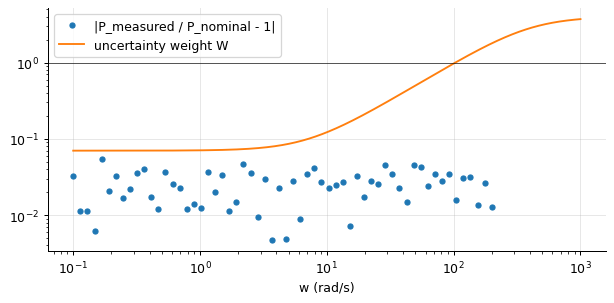

the weight lies above the data at every measured frequency: True; it crosses 1 at 103 rad/s
limits: the delay allows a crossover up to ~248 rad/s; the resonance (gain peak 10x at 80 rad/s) requires |L(j80)| << 1, i.e. a crossover well below 20 rad/s; the 0.5 s settling needs a dominant pole near sigma = 4/0.5 = 8 1/s


In [4]:
W_data = np.abs(resid - 1)                                           # multiplicative error of the nominal model (with delay) against the data
W = sy.tf([0.5 / 50.0, 0.07], [1.0 / 400.0, 1.0])                   # a first-order envelope above it
wg = np.logspace(-1, 3, 2000)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.loglog(w, W_data, "o", ms=4, label="|P_measured / P_nominal - 1|"); ax.loglog(wg, np.abs(fr.freqresp(W, wg)), label="uncertainty weight W"); ax.axhline(1, color="k", lw=0.5); ax.legend(); ax.set_xlabel("w (rad/s)"); plt.show()
print(f"the weight lies above the data at every measured frequency: {bool(np.all(np.abs(fr.freqresp(W, w)) >= W_data))}; it crosses 1 at {wg[np.argmax(np.abs(fr.freqresp(W, wg)) > 1)]:.0f} rad/s")
lim = rb.rhp_limits(P_nom, delay=delay)
print(f"limits: the delay allows a crossover up to ~{lim['w_c_max_from_delay']:.0f} rad/s; the resonance (gain peak {1 / (2 * zr):.0f}x at {wr:.0f} rad/s) requires |L(j{wr:.0f})| << 1, i.e. a crossover well below {wr / 4:.0f} rad/s; the 0.5 s settling needs a dominant pole near sigma = 4/0.5 = 8 1/s")

With the resonance in the nominal model the remaining uncertainty is small - a few percent at low frequency,
rising above one beyond 100 rad/s where the model has not been measured - so robust stability (|WT| < 1,
notebook 14) will be easy to satisfy and the real limit is the resonance itself: the loop gain at 80 rad/s
must stay well below one, which confines the crossover to about 15 rad/s. The settling-time specification
needs closed-loop poles with σ ≈ 8 s⁻¹ - compatible, but with little room.

## 4. A classical design: lead compensation

In [5]:
def simulate_digital(controller_ss, dt, T=1.5, step=10.0, u_lim=12.0, observer=None, K=None, Nbar=None):
    # the plant (nominal model with delay) at 1 kHz, the controller discretised at dt: either an output-feedback
    # controller (controller_ss from the error e to u) or observer-based state feedback (u = -K xhat + Nbar r)
    Pz = dc.c2d(P_nom.to_ss(), 0.001)
    nd = int(round(delay / 0.001)); N = int(T / 0.001); sub = int(round(dt / 0.001))
    xp = np.zeros(Pz.n); uh = np.zeros(N + nd + 1); yh = np.zeros(N); ur = np.zeros(N)
    xc = np.zeros(controller_ss.n) if controller_ss is not None else None
    xo = np.zeros(observer.n) if observer is not None else None
    u = 0.0
    for k in range(N):
        y = (Pz.C @ xp)[0]; yh[k] = y
        if k % sub == 0:                                               # the controller runs at its own rate
            if observer is None:
                e = step - y
                u = float(np.clip((controller_ss.C @ xc + controller_ss.D @ [e])[0], -u_lim, u_lim))
                xc = controller_ss.A @ xc + controller_ss.B @ [e]
            else:
                u = float(np.clip((-K @ xo)[0] + Nbar * step, -u_lim, u_lim))
                xo = observer.A @ xo + observer.B @ [u, y]
        ur[k] = u; uh[k + nd] = u
        xp = Pz.A @ xp + Pz.B @ [uh[k]]
    t_ = np.arange(N) * 0.001
    return t_, yh, ur, rs.step_info(t_, yh, final=step)
rows = []
for wc, pm in ((12.0, 50.0), (15.0, 55.0), (20.0, 60.0)):
    d = dg.design_lead(P_nom, w_c=wc, pm_target_deg=pm + np.degrees(wc * delay))   # ask for the delay's phase in advance
    L = sy.series(d["controller"], P_nom)
    m = fr.margins(L, delay=delay)
    rob = rb.multiplicative_robustness(L, W)
    t_, yh, ur, info = simulate_digital(dc.c2d(d["controller"], 0.001, "tustin").to_ss(), 0.001)
    rows.append((wc, d["n_leads"], m["w_gc"], m["phase_margin"], m["gain_margin"], rb.sensitivity_peak(L)["Ms"], rob["peak_WT"], info["overshoot"], info["settling_time"], np.max(np.abs(ur))))
print(pd.DataFrame(rows, columns=["target w_c", "leads", "w_gc", "PM (deg)", "GM", "Ms", "|WT| peak", "overshoot %", "settling (s)", "peak V"]).to_string(index=False, float_format="%.2f"))

 target w_c  leads  w_gc  PM (deg)   GM   Ms  |WT| peak  overshoot %  settling (s)  peak V
      12.00      2 12.00     55.00 3.04 1.71       0.20        14.71          0.63   10.75
      15.00      2 15.00     60.00 2.84 1.67       0.33         0.04          0.73   12.00
      20.00      2 20.00     65.00 2.11 2.26       1.11         0.10          1.00   12.00


A lead design on the nominal model (asking for the delay's phase in advance) gives robust loops - M_s below
1.7, the resonance a factor of five below unity gain, |WT| far below one - and a 10 rad step that stays within
the 12 V supply. But none meets the 0.5 s settling: the two cascaded leads leave a slow closed-loop pole near
their zeros, and the response creeps to its final value for 0.6-0.7 s. Pushing the crossover does not help;
the structure does not fit the specification.

## 5. Observer-based state feedback on the identified model

In [6]:
from englincontrol import statespace as sp
Pss = P_nom.to_ss()                                                  # 5 states: motor (2), integrator, resonance (2)
A, B, C = Pss.A, Pss.B, Pss.C
r_lqr = sp.lqr(A, B, 10.0 * C.T @ C, np.array([[1.0]]))
K = r_lqr["K"]; Nbar = sp.reference_gain(A, B, C, K)
print("LQR on the position output: closed-loop poles", np.round(np.sort_complex(r_lqr["closed_loop_poles"]), 1))
rows = []
for scale in (1.0, 2.0, 4.0, 8.0):
    L_obs = sp.observer_gain(A, C, -scale * np.array([15.0, 16.0, 17.0, 18.0, 19.0]))
    comp = sy.ss(A - B @ K - L_obs @ C, L_obs, K, np.zeros((1, 1)))      # the compensator from y to -u
    L_in = sy.series(P_nom, comp.to_tf())                                 # the loop at the plant input
    dist = rb.nyquist_distance(L_in); m = fr.margins(L_in, delay=delay); rob = rb.multiplicative_robustness(L_in, W)
    obs_z = dc.c2d(sy.ss(A - L_obs @ C, np.hstack([B, L_obs]), np.eye(5), np.zeros((5, 2))), 0.001)
    t_, yh, ur, info = simulate_digital(None, 0.001, observer=obs_z, K=K, Nbar=Nbar)
    rows.append((f"-{15 * scale:.0f} .. -{19 * scale:.0f}", dist["distance"], 1 / dist["distance"], m["phase_margin"], m["gain_margin"], rob["peak_WT"], info["overshoot"], info["settling_time"], np.max(np.abs(ur))))
print(pd.DataFrame(rows, columns=["observer poles", "min |1 + L|", "Ms", "PM (deg)", "GM", "|WT| peak", "overshoot %", "settling (s)", "peak V"]).to_string(index=False, float_format="%.2f"))

LQR on the position output: closed-loop poles [-34.1 +0.j  -19.7-27.2j -19.7+27.2j  -4.9-80.2j  -4.9+80.2j]


observer poles  min |1 + L|   Ms  PM (deg)   GM  |WT| peak  overshoot %  settling (s)  peak V
    -15 .. -19         0.64 1.56     50.85 2.97       0.16        11.84          0.27   12.00
    -30 .. -38         0.43 2.34     32.32 1.76       0.38        14.65          0.38   12.00
    -60 .. -76         0.37 2.73     22.82 1.55       0.66        15.96          0.41   12.00
  -120 .. -152         0.43 2.33     22.05 1.73       0.72        12.36          0.35   12.00


State feedback designed by LQR on the identified five-state model, with the state reconstructed by an
observer from the position measurement, meets the settling time easily - and the observer's speed decides
the robustness, the other way round from the textbook rule: the *slowest* observer, with poles near the
regulator's, gives the largest distance from −1 (M_s = 1.56, 51° of phase margin), while observers three to
eight times faster push the loop gain up near the resonance and cut the margin to 20-30°. The rule "observer
poles 3-5 times faster than the controller's" assumes the plant is well modelled at those frequencies; here
it is not, and the data decide. The slow-observer design meets every specification: 0.27 s settling, 51°,
|WT| = 0.15, 12 V peak.

## 6. Digital implementation

closed-loop bandwidth 21.1 rad/s -> the rules suggest dt between 9 and 28 ms; the resonance at 80 rad/s must stay below the Nyquist frequency with margin: dt < 20 ms
dt =    1 ms: 10 rad step: overshoot 11.8 %, 2 % settling 0.267 s, peak 12.0 V, saturated for 24 ms
dt =    5 ms: 10 rad step: overshoot 13.7 %, 2 % settling 0.271 s, peak 12.0 V, saturated for 25 ms
dt =   10 ms: 10 rad step: overshoot 16.3 %, 2 % settling 0.378 s, peak 12.0 V, saturated for 30 ms


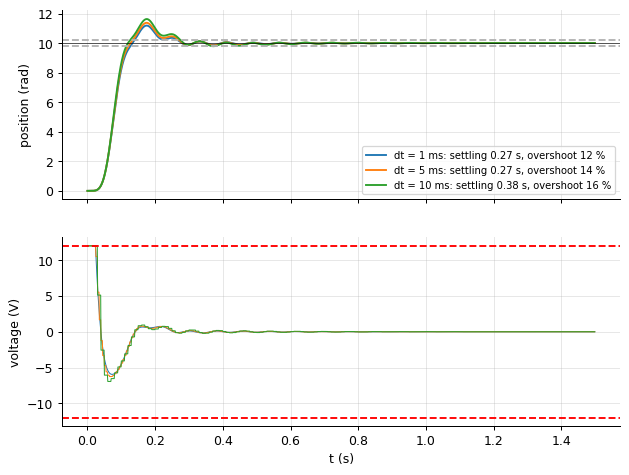

In [7]:
L_obs = sp.observer_gain(A, C, -np.array([15.0, 16.0, 17.0, 18.0, 19.0]))
comp = sy.ss(A - B @ K - L_obs @ C, L_obs, K, np.zeros((1, 1)))
L_in = sy.series(P_nom, comp.to_tf())
T_cl = sy.feedback(L_in)
wb = fr.bandwidth(T_cl)
rules = dc.sample_rate_rules(wb)
print(f"closed-loop bandwidth {wb:.1f} rad/s -> the rules suggest dt between {rules['dt_min'] * 1000:.0f} and {rules['dt_max'] * 1000:.0f} ms; the resonance at {wr:.0f} rad/s must stay below the Nyquist frequency with margin: dt < {np.pi / wr / 2 * 1000:.0f} ms")
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
for dt in (0.001, 0.005, 0.01):
    obs_z = dc.c2d(sy.ss(A - L_obs @ C, np.hstack([B, L_obs]), np.eye(5), np.zeros((5, 2))), dt)
    t_, yh, ur, info = simulate_digital(None, dt, observer=obs_z, K=K, Nbar=Nbar)
    axes[0].plot(t_, yh, label=f"dt = {dt * 1000:.0f} ms: settling {info['settling_time']:.2f} s, overshoot {info['overshoot']:.0f} %"); axes[1].plot(t_, ur, lw=0.8)
    print(f"dt = {dt * 1000:4.0f} ms: 10 rad step: overshoot {info['overshoot']:.1f} %, 2 % settling {info['settling_time']:.3f} s, peak {np.max(np.abs(ur)):.1f} V, saturated for {np.sum(np.abs(ur) >= 12.0):.0f} ms")
axes[0].axhline(10, color="k", lw=0.5); axes[0].axhline(10.2, color="0.7", ls="--"); axes[0].axhline(9.8, color="0.7", ls="--"); axes[0].legend(fontsize=8); axes[0].set_ylabel("position (rad)"); axes[1].axhline(12, color="r", ls="--"); axes[1].axhline(-12, color="r", ls="--"); axes[1].set_ylabel("voltage (V)"); axes[1].set_xlabel("t (s)")
plt.show()
dt = 0.005
info_final = simulate_digital(None, dt, observer=dc.c2d(sy.ss(A - L_obs @ C, np.hstack([B, L_obs]), np.eye(5), np.zeros((5, 2))), dt), K=K, Nbar=Nbar)[3]
m_final = fr.margins(L_in, delay=delay + dt / 2 + dt)                 # the hold's half sample and one sample of computation delay

The observer and gain are discretised (ZOH on the observer, the gain unchanged) and run at 1, 5 and 10 ms
against the plant with its delay and the 12 V limit. At 5 ms (ω_bΔt ≈ 0.1, and the 80 rad/s resonance well
inside the Nyquist band) the response is indistinguishable from the 1 ms one and meets the specification;
at 10 ms the hold's delay begins to show. 200 Hz it is, with an anti-aliasing filter above 150 rad/s, the
measurement read and the voltage written at the start of each period.

## 7. The report

In [8]:
report = f'''# Position servo: identification, design and digital implementation

Data: motor PRBS test (output-error fit at 20 Hz), servo sine sweep (60 frequencies).
Model: motor {Gm_tf}, servo gain {gear:.1f}, structural resonance {wr:.0f} rad/s (zeta {zr:.2f}), delay {delay * 1000:.1f} ms;
       residual uncertainty bounded by W = {W} (crosses 1 at ~100 rad/s).
Limits: the resonance confines the crossover to ~15 rad/s (the delay alone would allow {1 / delay:.0f}); the 0.5 s settling needs sigma ~ 8 1/s.
Classical design: cascaded leads at 12-20 rad/s are robust (Ms < 1.7) but settle in 0.6-0.7 s: a slow closed-loop pole from the lead pair.
Chosen design: LQR state feedback (q = 10 on the position) on the identified 5-state model with a Luenberger observer at poles -15 .. -19 -
       the slowest tried, and the most robust: min |1 + L| = {rb.nyquist_distance(L_in)['distance']:.2f} (Ms {rb.sensitivity_peak(L_in)['Ms']:.2f}), phase margin {m_final['phase_margin']:.0f} deg with hold and computation delay,
       |W T| peak {rb.multiplicative_robustness(L_in, W)['peak_WT']:.2f} < 1. Faster observers (x2 to x8) cut the margin to 20-30 deg: the resonance punishes high-frequency loop gain.
Implementation: 200 Hz (w_b dt = {wb * dt:.2f}), observer discretised by ZOH; 10 rad step: overshoot {info_final['overshoot']:.0f} %, settling {info_final['settling_time']:.2f} s (spec 0.5), peak 12 V (brief saturation).
Caveats: linear friction and a single resonance assumed; the uncertainty weight comes from one sweep; the model above 100 rad/s is uncertain and above 200 rad/s unmeasured, hence the anti-aliasing filter.
'''
print(report)

# Position servo: identification, design and digital implementation

Data: motor PRBS test (output-error fit at 20 Hz), servo sine sweep (60 frequencies).
Model: motor TransferFunction(0.2682s + 247.3 / s^2 + 22.15s + 61.65), servo gain 49.7, structural resonance 80 rad/s (zeta 0.05), delay 4.0 ms;
       residual uncertainty bounded by W = TransferFunction(4s + 28 / s + 400) (crosses 1 at ~100 rad/s).
Limits: the resonance confines the crossover to ~15 rad/s (the delay alone would allow 248); the 0.5 s settling needs sigma ~ 8 1/s.
Classical design: cascaded leads at 12-20 rad/s are robust (Ms < 1.7) but settle in 0.6-0.7 s: a slow closed-loop pole from the lead pair.
Chosen design: LQR state feedback (q = 10 on the position) on the identified 5-state model with a Luenberger observer at poles -15 .. -19 -
       the slowest tried, and the most robust: min |1 + L| = 0.64 (Ms 1.56), phase margin 47 deg with hold and computation delay,
       |W T| peak 0.16 < 1. Faster observers (x2 to 

The report follows the course's logic: identify what the data support, model what they show and bound what
they do not, let the limits set the bandwidth, try the classical structure and recognise when it does not
fit, design in state space on the identified model and check the loop that is actually closed, discretise at
a rate the analysis justifies, and verify on the full model with the real actuator limit. Its central finding
- that the observer should be slow here - came from the data and the robustness check, not from a rule; every
number in it can be traced to a cell above, which is what a design document for a real servo should allow.

## Inside the analysis: why the faster observer hurt

In [9]:
for scale in (1.0, 8.0):
    L_o = sp.observer_gain(A, C, -scale * np.array([15.0, 16.0, 17.0, 18.0, 19.0]))
    comp_ = sy.ss(A - B @ K - L_o @ C, L_o, K, np.zeros((1, 1)))
    L_i = sy.series(P_nom, comp_.to_tf())
    print(f"observer poles x{scale:.0f}: |L| at the resonance frequency {wr:.0f} rad/s = {abs(fr.freqresp(L_i, wr)):.3f}; at 2 x the crossover = {abs(fr.freqresp(L_i, 30.0)):.3f}")

observer poles x1: |L| at the resonance frequency 80 rad/s = 0.218; at 2 x the crossover = 0.327
observer poles x8: |L| at the resonance frequency 80 rad/s = 0.255; at 2 x the crossover = 1.078


## Exercises
1. Replace the LQR gain by a pole-placement gain with the same dominant poles and repeat the observer scan. Is the slow-observer advantage a property of LQR or of the plant?
2. Add integral action to the state-space design (notebook 10's augmentation) so that a 10 % error in the servo gain leaves no position offset, and check what it costs in margins and settling time.
3. **Implement it yourself:** write the complete digital controller as a difference-equation function `u = controller(y, r)` with its internal state (the discretised observer and the gain), and run it against the plant model at 200 Hz with the 12 V limit; the result must reproduce section 6's response.